# Pontificia Universidad Javeriana

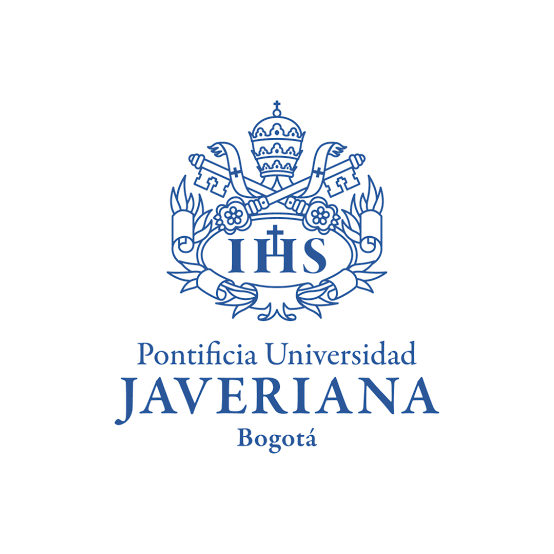

## Taller Salario , Procesamiento de Datos a Gran Escala

Autor: Samuel Rodríguez Murillo  
Docente: John Corredor  
Curso: Procesamiento de Datos a Gran Escala  
Semestre: 2026-3  
Fecha de entrega: 18 de noviembre de 2026  
Tema: Análisis de datos de ICTUS y aplicación de modelos supervisados con PySpark MLlib  

---



## Contexto
Este taller de Procesamiento de Datos a Gran Escala utiliza Census Income (Adult), publicado en UCI, para clasificar ingresos anuales en ≤50.000 USD y >50.000 USD. Los registros proceden de una extracción de la base censal estadounidense de 1994 y reúnen características demográficas, educativas y laborales. UCI documenta 48.842 observaciones y 14 variables explicativas; la carga confirmó estas dimensiones.

Se sigue CRISP-DM: conocimiento, preparación, modelado, evaluación y conclusiones. El membrete anterior conserva los datos del original, incluido su tema histórico de ICTUS; el ejercicio desarrollado desde aquí corresponde a ingresos. La asociación estadística no establece causalidad ni permite trasladar directamente los resultados a salarios actuales o a otras poblaciones.

## Objetivos
Objetivo general: implementar y comparar cinco clasificadores de PySpark MLlib para predecir ingresos superiores a 50.000 dólares.

- Conocer la estructura, calidad y distribución de los datos.
- Preparar las variables sin ajustar transformaciones con el conjunto de prueba.
- Aplicar regresión logística, árbol de decisión, Random Forest, GBT y LinearSVC.
- Comparar exactitud, discriminación y recuperación de la clase positiva.
- Formular conclusiones y recomendaciones sustentadas en la evaluación.

### Preparación del entorno

In [1]:
# Bibliotecas generales
import urllib.request
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import findspark

In [2]:
findspark.init('/mnt/sda1/Cluster/Spark')

In [3]:
# Bibliotecas de Spark
from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, StringType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, Imputer
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier, GBTClassifier, LinearSVC
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

### Configuración de la sesión Spark

In [4]:
configura = SparkConf().set("spark.ui.port", "37016")
configura.setAppName("RodriguezSalario1055")

In [5]:
sparkRodriguezM = SparkSession.builder.config(conf=configura).getOrCreate()
sparkContextoRodriguezM = sparkRodriguezM.sparkContext

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


In [6]:
sparkRodriguezM

### Descarga y carga del dataset Census Income
El cuaderno descarga automáticamente el ZIP oficial de UCI y extrae `adult.data` y `adult.test` en la carpeta local `datos_adult`, dentro del directorio de trabajo. No se requiere una descarga manual.

Se leen las líneas en el proceso principal y se distribuyen con `parallelize`; el lector CSV de Spark interpreta los tipos. Así los ejecutores no necesitan acceder al disco local del notebook. Esta carga acotada es adecuada para Adult, pero no para archivos que excedan la memoria del proceso principal.

In [7]:
carpetaDatos = Path("datos_adult")
carpetaDatos.mkdir(exist_ok=True)

In [8]:
url = "https://archive.ics.uci.edu/static/public/20/census+income.zip"
urllib.request.urlretrieve(url, carpetaDatos / "census_income.zip")

(PosixPath('datos_adult/census_income.zip'),
 <http.client.HTTPMessage at 0x72d5d71d4110>)

In [9]:
with zipfile.ZipFile(carpetaDatos / "census_income.zip") as archivoZIP:
    archivoZIP.extract("adult.data", carpetaDatos)
    archivoZIP.extract("adult.test", carpetaDatos)

In [10]:
nombresColumnas = ["Edad", "TipoTrabajo", "PesoCensal", "Educacion", "NivelEducativo",
                   "EstadoCivil", "Ocupacion", "Relacion", "Raza", "Sexo",
                   "GananciaCapital", "PerdidaCapital", "HorasSemana", "PaisOrigen", "Ingresos"]
columnasNumericas = ["Edad", "PesoCensal", "NivelEducativo", "GananciaCapital", "PerdidaCapital", "HorasSemana"]
columnasTexto = [c for c in nombresColumnas if c not in columnasNumericas]

In [11]:
esquema = StructType([StructField(c, IntegerType() if c in columnasNumericas else StringType(), True)
                       for c in nombresColumnas])

In [12]:
with open(carpetaDatos / "adult.data", encoding="utf-8") as archivoTrain:
    lineasTrain = [linea.strip() for linea in archivoTrain if linea.strip()]
with open(carpetaDatos / "adult.test", encoding="utf-8") as archivoTest:
    lineasTest = [linea.strip() for linea in archivoTest if linea.strip() and not linea.lstrip().startswith("|")]

In [13]:
df00Train = sparkRodriguezM.read.schema(esquema).option("mode", "FAILFAST").option(
    "ignoreLeadingWhiteSpace", True).option("ignoreTrailingWhiteSpace", True).csv(
    sparkContextoRodriguezM.parallelize(lineasTrain))

In [14]:
df00Test = sparkRodriguezM.read.schema(esquema).option("mode", "FAILFAST").option(
    "ignoreLeadingWhiteSpace", True).option("ignoreTrailingWhiteSpace", True).csv(
    sparkContextoRodriguezM.parallelize(lineasTest))

### 1.- Diagnóstico y tratamiento de datos
Se conserva la partición original de UCI. La primera línea de `adult.test`, iniciada por `|`, es un comentario y se excluye antes de leer el CSV. El EDA se concentra en entrenamiento; prueba se reserva para controles de integridad y evaluación final.

### Descripción de las variables
| Variable | Tipo | Descripción |
|---|---|---|
| Edad | Entero | Edad en años |
| TipoTrabajo | Texto | Clase de empleador o trabajo |
| PesoCensal | Entero | `fnlwgt`, peso de representación censal |
| Educacion | Texto | Categoría educativa |
| NivelEducativo | Entero | Codificación ordinal de educación |
| EstadoCivil | Texto | Situación conyugal |
| Ocupacion | Texto | Grupo ocupacional |
| Relacion | Texto | Relación dentro del hogar |
| Raza | Texto | Categoría registrada en el censo |
| Sexo | Texto | Categoría registrada en el censo |
| GananciaCapital | Entero | Ganancias de capital en dólares |
| PerdidaCapital | Entero | Pérdidas de capital en dólares |
| HorasSemana | Entero | Horas trabajadas por semana |
| PaisOrigen | Texto | País de origen |
| Ingresos | Texto | Objetivo: ≤50K o >50K |

Raza y Sexo son categorías del registro histórico; no se interpretan como causas del ingreso.

In [15]:
totalTrainOriginal = df00Train.count()
totalTestOriginal = df00Test.count()
print("Entrenamiento:", totalTrainOriginal, "filas;", len(df00Train.columns), "columnas")
print("Prueba:", totalTestOriginal, "filas;", len(df00Test.columns), "columnas")
print("Total:", totalTrainOriginal + totalTestOriginal)

Entrenamiento: 32561 filas; 15 columnas
Prueba: 16281 filas; 15 columnas
Total: 48842


La carga confirmó 48.842 observaciones: 32.561 de entrenamiento y 16.281 de prueba. Cada archivo tiene 15 columnas, correspondientes a 14 variables explicativas y la etiqueta. Se conserva la separación original de UCI para evaluar todos los modelos con los mismos registros.

In [16]:
df00Train.printSchema()
df00Train.show(5, truncate=False)

root
 |-- Edad: integer (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- PesoCensal: integer (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- NivelEducativo: integer (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: integer (nullable = true)
 |-- PerdidaCapital: integer (nullable = true)
 |-- HorasSemana: integer (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingresos: string (nullable = true)

+----+----------------+----------+---------+--------------+------------------+-----------------+-------------+-----+------+---------------+--------------+-----------+-------------+--------+
|Edad|TipoTrabajo     |PesoCensal|Educacion|NivelEducativo|EstadoCivil       |Ocupacion        |Relacion     |Raza |Sexo  |GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen

### Limpieza de texto y etiquetas
Se recortan espacios, se convierten `?` y cadenas vacías en nulos y se elimina únicamente el punto final de la etiqueta. Son reglas fijas aplicadas por igual a ambos conjuntos, sin estimar parámetros.

In [17]:
df01Train = df00Train
for c in columnasTexto:
    df01Train = df01Train.withColumn(c, F.when(F.trim(F.col(c)).isin("?", ""), None).otherwise(F.trim(F.col(c))))
df01Train = df01Train.withColumn("Ingresos", F.regexp_replace("Ingresos", r"\.$", ""))

In [18]:
df01Test = df00Test
for c in columnasTexto:
    df01Test = df01Test.withColumn(c, F.when(F.trim(F.col(c)).isin("?", ""), None).otherwise(F.trim(F.col(c))))
df01Test = df01Test.withColumn("Ingresos", F.regexp_replace("Ingresos", r"\.$", ""))

### Identificación de valores faltantes y duplicados

In [19]:
df01Train.select([F.count(F.when(F.col(c).isNull(), 1)).alias(c) for c in nombresColumnas]).show(truncate=False)
df01Test.select([F.count(F.when(F.col(c).isNull(), 1)).alias(c) for c in nombresColumnas]).show(truncate=False)

+----+-----------+----------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|Edad|TipoTrabajo|PesoCensal|Educacion|NivelEducativo|EstadoCivil|Ocupacion|Relacion|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingresos|
+----+-----------+----------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|0   |1836       |0         |0        |0             |0          |1843     |0       |0   |0   |0              |0             |0          |583       |0       |
+----+-----------+----------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+

+----+-----------+----------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+--------+
|Edad|TipoTrabajo|PesoCensal|Educacion|NivelE

Los faltantes se concentran en TipoTrabajo, Ocupacion y PaisOrigen. En entrenamiento aparecen 1.836, 1.843 y 583 nulos, respectivamente, aproximadamente el 5,64%, 5,66% y 1,79%. En prueba se encuentran 963, 966 y 274. No hay faltantes numéricos ni en la etiqueta. Los conteos son por columna y no deben sumarse como si correspondieran a personas diferentes.

In [20]:
duplicadosTrain = totalTrainOriginal - df01Train.dropDuplicates().count()
duplicadosTest = totalTestOriginal - df01Test.dropDuplicates().count()
coincidencias = df01Train.intersect(df01Test).count()
print("Filas repetidas en train:", duplicadosTrain)
print("Filas repetidas en test:", duplicadosTest)
print("Perfiles completos distintos compartidos:", coincidencias)

26/11/23 21:08:11 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Filas repetidas en train: 24
Filas repetidas en test: 5
Perfiles completos distintos compartidos: 23


### Tratamiento de duplicados
Se detectaron 24 filas repetidas en entrenamiento, 5 en prueba y 23 perfiles completos distintos compartidos entre ambos archivos. No existe un identificador personal que permita demostrar que dos perfiles iguales corresponden a la misma persona. Se conservan los duplicados y las particiones oficiales: borrarlos podría modificar las frecuencias poblacionales. Se reportan también coincidencias entre archivos como limitación de independencia; no se utiliza prueba para eliminar o seleccionar registros de entrenamiento. Una evaluación futura puede contrastarse con una partición por grupos de perfiles.

In [21]:
assert df01Train.filter(F.col("Ingresos").isNull() | ~F.col("Ingresos").isin("<=50K", ">50K")).count() == 0, "Etiquetas no válidas en train"
assert df01Test.filter(F.col("Ingresos").isNull() | ~F.col("Ingresos").isin("<=50K", ">50K")).count() == 0, "Etiquetas no válidas en test"

In [22]:
df02Train = df01Train.withColumn("Salario", F.when(F.col("Ingresos") == ">50K", 1.0).otherwise(0.0))
df02Test = df01Test.withColumn("Salario", F.when(F.col("Ingresos") == ">50K", 1.0).otherwise(0.0))

### Resumen estadístico y distribución del objetivo

In [23]:
df02Train.select(columnasNumericas).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show()

[Stage 44:>                                                       (0 + 10) / 10]

+-------+-----------------+------------------+------------------+------------------+-----------------+------------------+
|summary|             Edad|        PesoCensal|    NivelEducativo|   GananciaCapital|   PerdidaCapital|       HorasSemana|
+-------+-----------------+------------------+------------------+------------------+-----------------+------------------+
|  count|            32561|             32561|             32561|             32561|            32561|             32561|
|   mean|38.58164675532078|189778.36651208502|  10.0806793403151|1077.6488437087312|  87.303829734959|40.437455852092995|
| stddev|13.64043255358135|105549.97769702226|2.5727203320673864| 7385.292084840342|402.9602186489997|12.347428681731845|
|    min|               17|             12285|                 1|                 0|                0|                 1|
|    25%|               28|            117814|                 9|                 0|                0|                40|
|    50%|               

La edad media es de 38,58 años y la mediana de 37; la mitad central de las edades está entre 28 y 48 años. Las horas semanales tienen una media de 40,44 y una mediana de 40. GananciaCapital y PerdidaCapital presentan mediana y percentil 75 iguales a cero, aunque sus máximos son 99.999 y 4.356 dólares. Sus distribuciones se concentran en cero y presentan valores altos en una parte de la muestra, sin que esto implique por sí solo errores.

In [24]:
distribucion = df02Train.groupBy("Ingresos").count().withColumn("Porcentaje", 100 * F.col("count") / totalTrainOriginal)
distribucion.orderBy("Ingresos").show()
distribucionGrafica = distribucion.orderBy("Ingresos").toPandas()

+--------+-----+------------------+
|Ingresos|count|        Porcentaje|
+--------+-----+------------------+
|   <=50K|24720| 75.91904425539757|
|    >50K| 7841|24.080955744602438|
+--------+-----+------------------+



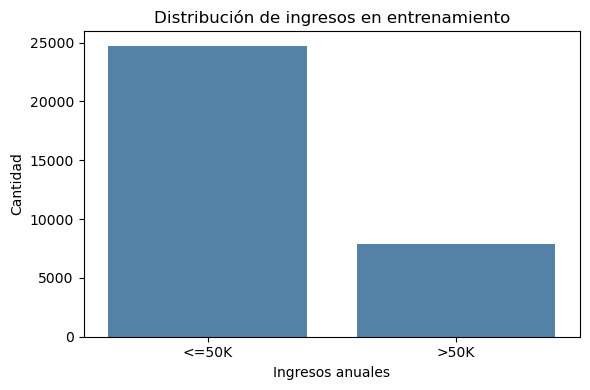

In [25]:
plt.figure(figsize=(6,4))
sns.barplot(data=distribucionGrafica, x="Ingresos", y="count", color="steelblue")
plt.title("Distribución de ingresos en entrenamiento")
plt.xlabel("Ingresos anuales")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

La gráfica muestra un desbalance a favor de los ingresos menores o iguales a 50.000 dólares: 24.720 registros, el 75,92% del entrenamiento. La clase >50K contiene 7.841 registros, el 24,08%. Hay aproximadamente tres registros de la clase mayoritaria por cada positivo, por lo que Accuracy debe contrastarse con Recall y F1 de la clase >50K.

### Gráficas de los datos
Se agregan frecuencias en Spark y solo se llevan tablas pequeñas a Pandas. Los valores extremos de capital se revisan con los cuantiles anteriores; un valor alto no se elimina automáticamente porque puede ser válido.

In [26]:
frecuenciasEdad = df02Train.groupBy("Edad").count().orderBy("Edad").toPandas()

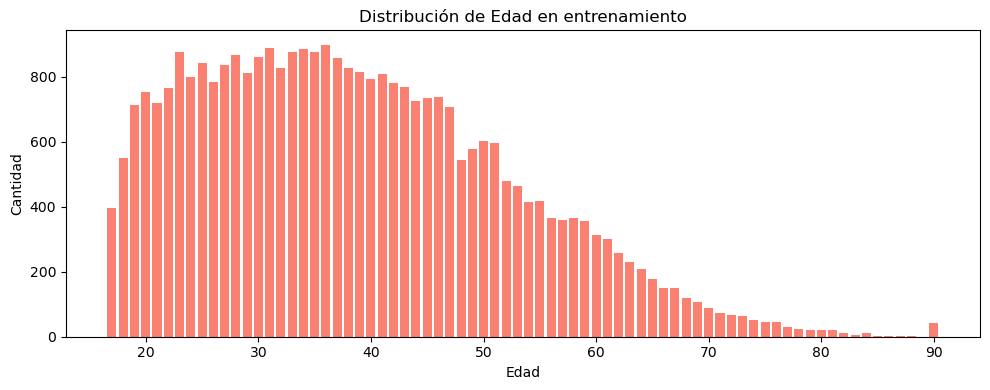

In [27]:
plt.figure(figsize=(10,4))
plt.bar(frecuenciasEdad["Edad"], frecuenciasEdad["count"], color="salmon")
plt.title("Distribución de Edad en entrenamiento")
plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

La distribución presenta frecuencias altas entre los veinte y los cuarenta años. Desde las edades medias, la cantidad disminuye progresivamente y quedan pocos registros de personas de edad avanzada. La media de 38,58 años y la mediana de 37 son coherentes con esta concentración, dentro de un rango de 17 a 90 años.

In [28]:
frecuenciasHorasSemana = df02Train.groupBy("HorasSemana").count().orderBy("HorasSemana").toPandas()

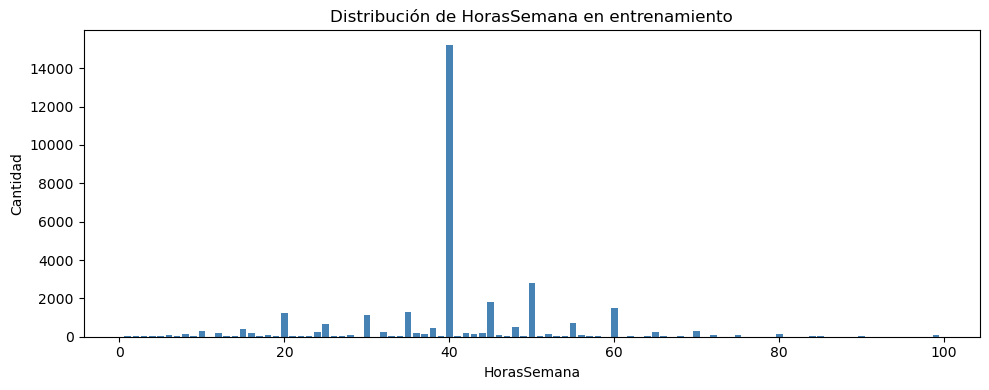

In [29]:
plt.figure(figsize=(10,4))
plt.bar(frecuenciasHorasSemana["HorasSemana"], frecuenciasHorasSemana["count"], color="steelblue")
plt.title("Distribución de HorasSemana en entrenamiento")
plt.xlabel("HorasSemana")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

La mayor concentración aparece en 40 horas semanales, con una barra muy superior a las demás. Se observan agrupaciones menores en jornadas de 20, 45, 50 y 60 horas. La mediana de 40 y los percentiles 25 y 75, de 40 y 45 horas, confirman la concentración cerca de una jornada de tiempo completo. Los extremos de 1 y 99 horas requieren contexto antes de considerarse errores.

In [30]:
relacionNivelEducativo = df02Train.groupBy("NivelEducativo").agg(
    F.count("*").alias("Cantidad"), F.mean("Salario").alias("ProporcionMayor50K")).orderBy("NivelEducativo")
relacionNivelEducativo.show()
graficaNivelEducativo = relacionNivelEducativo.toPandas()

+--------------+--------+-------------------+
|NivelEducativo|Cantidad| ProporcionMayor50K|
+--------------+--------+-------------------+
|             1|      51|                0.0|
|             2|     168|0.03571428571428571|
|             3|     333|0.04804804804804805|
|             4|     646|0.06191950464396285|
|             5|     514|0.05252918287937743|
|             6|     933|0.06645230439442658|
|             7|    1175|0.05106382978723404|
|             8|     433|0.07621247113163972|
|             9|   10501|0.15950861822683554|
|            10|    7291|0.19023453572898094|
|            11|    1382|0.26121562952243127|
|            12|    1067|0.24835988753514526|
|            13|    5355| 0.4147525676937442|
|            14|    1723| 0.5565873476494486|
|            15|     576|           0.734375|
|            16|     413| 0.7409200968523002|
+--------------+--------+-------------------+



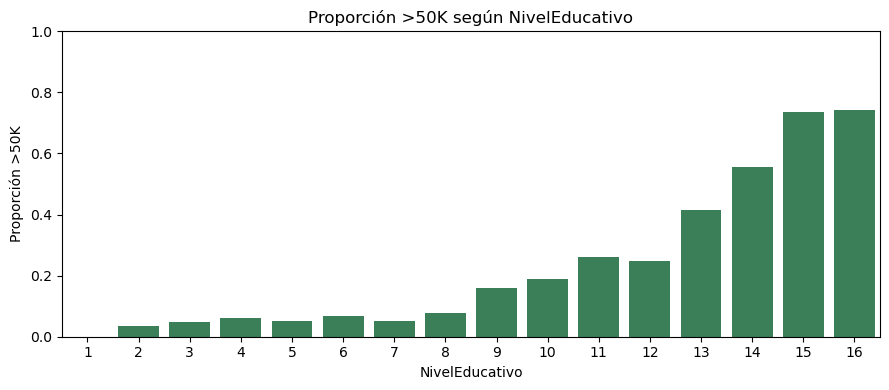

In [31]:
plt.figure(figsize=(9,4))
sns.barplot(data=graficaNivelEducativo, x="NivelEducativo", y="ProporcionMayor50K", color="seagreen")
plt.title("Proporción >50K según NivelEducativo")
plt.ylabel("Proporción >50K")
plt.ylim(0,1)
plt.tight_layout()
plt.show()

La proporción >50K tiende a aumentar con el nivel educativo, aunque no de forma estrictamente creciente. Pasa del 16% en el nivel 9 al 42% en el 13 y al 74% en el 16. Los grupos tienen tamaños distintos: el nivel 9 contiene 10.501 personas y el 16 solo 413. La relación respalda el interés predictivo de la educación, pero no demuestra que explique por sí sola las diferencias de ingresos.

In [32]:
relacionSexo = df02Train.groupBy("Sexo").agg(
    F.count("*").alias("Cantidad"), F.mean("Salario").alias("ProporcionMayor50K")).orderBy("Sexo")
relacionSexo.show()
graficaSexo = relacionSexo.toPandas()

+------+--------+-------------------+
|  Sexo|Cantidad| ProporcionMayor50K|
+------+--------+-------------------+
|Female|   10771|0.10946058861758426|
|  Male|   21790| 0.3057365764111978|
+------+--------+-------------------+



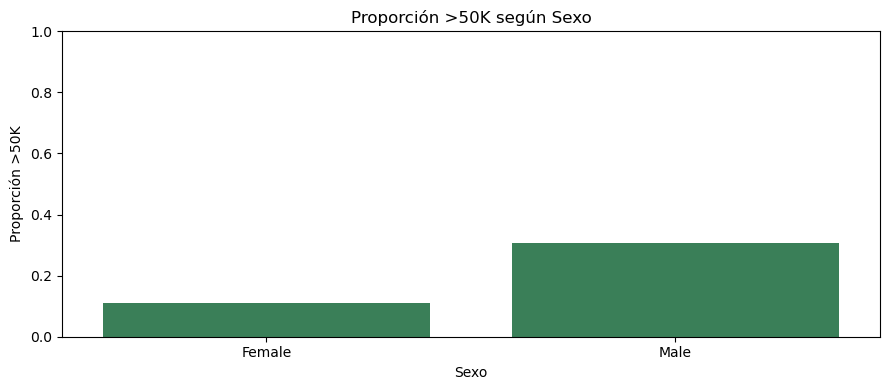

In [33]:
plt.figure(figsize=(9,4))
sns.barplot(data=graficaSexo, x="Sexo", y="ProporcionMayor50K", color="seagreen")
plt.title("Proporción >50K según Sexo")
plt.ylabel("Proporción >50K")
plt.ylim(0,1)
plt.tight_layout()
plt.show()

La proporción >50K es del 10,95% en Female y del 30,57% en Male, con una diferencia aproximada de 19,63 puntos porcentuales. Estos grupos contienen 10.771 y 21.790 registros. La gráfica describe una asociación histórica, sin separar el efecto de educación, ocupación u horas trabajadas. No permite concluir que las predicciones sean equitativas; para ello habría que comparar los errores por grupo.

#### Análisis correspondiente
El entrenamiento contiene 32.561 registros y una clase positiva minoritaria del 24,08%. La edad se concentra en adultos jóvenes y de edad media, y las horas trabajadas muestran un pico marcado en 40. Las variables de capital se concentran en cero y presentan extremos elevados, por lo que no basta describirlas mediante el promedio.

Los faltantes se localizan en tres variables categóricas y se representan como Desconocido. Se encontraron 24 filas repetidas en entrenamiento, 5 en prueba y 23 perfiles completos distintos compartidos entre ambos archivos. Se conservan las particiones originales, reconociendo las coincidencias como una limitación de independencia.

La proporción >50K aumenta en general con la educación y es mayor en Male que en Female. Estas asociaciones deben interpretarse junto con los tamaños de los grupos y no demuestran causalidad ni equidad del clasificador.

### 2.- Preparación de los datos y Pipeline
Se conserva `NivelEducativo` y se excluye `Educacion` por describir la misma característica. Se excluye `PesoCensal`: es un peso muestral, no un atributo salarial, y este ejercicio compara predicciones por registro sin ponderación poblacional. Se retiran `Ingresos` y cualquier columna auxiliar de las características.

Los faltantes categóricos se representan como `Desconocido`, sin estimar modas. Los numéricos se imputan por mediana de entrenamiento si aparecen faltantes. `StringIndexer` admite categorías nuevas y `OneHotEncoder` evita asignar un orden artificial. La tubería se ajusta solo con train. El escalamiento sin centrar mantiene vectores dispersos para los modelos lineales; los árboles usan el vector sin escalar. Se conservan las clases originales sin remuestreo y se analiza su efecto en las métricas.

In [34]:
varNumericas = ["Edad", "NivelEducativo", "GananciaCapital", "PerdidaCapital", "HorasSemana"]
varCategoricas = ["TipoTrabajo", "EstadoCivil", "Ocupacion", "Relacion", "Raza", "Sexo", "PaisOrigen"]
trainBase = df02Train.select(*varNumericas, *varCategoricas, "Salario").fillna("Desconocido", subset=varCategoricas)
testBase = df02Test.select(*varNumericas, *varCategoricas, "Salario").fillna("Desconocido", subset=varCategoricas)

In [35]:
imputador = Imputer(inputCols=varNumericas, outputCols=[c + "_IMP" for c in varNumericas], strategy="median")
indices = [StringIndexer(inputCol=c, outputCol=c + "_IND", handleInvalid="keep") for c in varCategoricas]

In [36]:
codificador = OneHotEncoder(inputCols=[c + "_IND" for c in varCategoricas],
                            outputCols=[c + "_OHE" for c in varCategoricas], dropLast=False)
varIndependientes = VectorAssembler(inputCols=[c + "_IMP" for c in varNumericas] + [c + "_OHE" for c in varCategoricas],
                                    outputCol="independientes")

In [37]:
escalador = StandardScaler(inputCol="independientes", outputCol="independientesEscaladas", withStd=True, withMean=False)
tuberia = Pipeline(stages=[imputador] + indices + [codificador, varIndependientes, escalador])

In [38]:
modeloPreparacion = tuberia.fit(trainBase)

In [39]:
train = modeloPreparacion.transform(trainBase).select("independientes", "independientesEscaladas", "Salario").cache()
test = modeloPreparacion.transform(testBase).select("independientes", "independientesEscaladas", "Salario").cache()

In [40]:
totalTrain = train.count()
totalTest = test.count()
assert totalTrain == totalTrainOriginal and totalTest == totalTestOriginal
assert train.select("Salario").distinct().count() == 2
assert test.select("Salario").distinct().count() == 2
train.show(5, truncate=70)

+----------------------------------------------------------------------+----------------------------------------------------------------------+-------+
|                                                        independientes|                                               independientesEscaladas|Salario|
+----------------------------------------------------------------------+----------------------------------------------------------------------+-------+
|(98,[0,1,2,4,9,16,26,40,46,52,55],[39.0,13.0,2174.0,40.0,1.0,1.0,1....|(98,[0,1,2,4,9,16,26,40,46,52,55],[2.859146866992894,5.053017165512...|    0.0|
|(98,[0,1,4,6,15,25,39,46,52,55],[50.0,13.0,13.0,1.0,1.0,1.0,1.0,1.0...|(98,[0,1,4,6,15,25,39,46,52,55],[3.665572906401146,5.05301716551268...|    0.0|
|(98,[0,1,4,5,17,32,40,46,52,55],[38.0,9.0,40.0,1.0,1.0,1.0,1.0,1.0,...|(98,[0,1,4,5,17,32,40,46,52,55],[2.785835408864871,3.49824265304724...|    0.0|
|(98,[0,1,4,5,15,32,39,47,52,55],[53.0,7.0,40.0,1.0,1.0,1.0,1.0,1.0,...|(98,[0,1,4,5,15,

El vector tiene 98 componentes y conserva una representación dispersa. Las verificaciones de tamaño y presencia de ambas clases terminaron sin errores, por lo que la preparación mantuvo los registros originales. No se observaron faltantes numéricos que requirieran reemplazo; el imputador queda incluido como parte del procedimiento.

## Implementación de modelos de Machine Learning usando MLlib
Se fijan configuraciones moderadas antes de evaluar prueba. No se optimizan hiperparámetros ni umbrales sobre test. Todos los modelos reciben los mismos registros y variables; solo cambia la escala para los métodos lineales.

#### Criterios de evaluación
Accuracy es la proporción total de aciertos. Precision positiva = TP/(TP+FP), Recall positivo = TP/(TP+FN), F1 positivo = 2TP/(2TP+FP+FN). Estas tres métricas corresponden exclusivamente a Salario = 1, no son promedios ponderados. Si un denominador es cero se informa 0 por convención.

AUC-ROC evalúa el orden de las puntuaciones a través de umbrales, no la calidad de una decisión concreta. Se usa `rawPrediction` en los cinco modelos, incluido LinearSVC, que no ofrece probabilidades. La matriz usa filas reales y columnas predichas en el orden [0,1]: [[TN,FP],[FN,TP]]. Se prioriza F1 positivo como criterio general, AUC como desempate, y se identifica por separado el mayor Recall.

In [41]:
evaluadorAccuracy = MulticlassClassificationEvaluator(labelCol="Salario", predictionCol="prediction", metricName="accuracy")
evaluadorAUC = BinaryClassificationEvaluator(labelCol="Salario", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
resultadosModelos = []

### Regresión Logística

Estima una probabilidad con una combinación lineal de características. Sirve como referencia interpretable para comparar relaciones lineales frente a interacciones más complejas.

In [42]:
RLog = LogisticRegression(featuresCol="independientesEscaladas", labelCol="Salario", maxIter=100, regParam=0.01, standardization=False)

In [43]:
modeloRLog = RLog.fit(train)

In [44]:
predRLog = modeloRLog.transform(test).cache()

#### Evaluación de Regresión Logística

In [45]:
accuracyRLog = evaluadorAccuracy.evaluate(predRLog)
AUCRLog = evaluadorAUC.evaluate(predRLog)

In [46]:
conteosRLog = predRLog.groupBy("Salario", "prediction").count().collect()
matrizRLog = np.zeros((2, 2), dtype=int)
for fila in conteosRLog:
    matrizRLog[int(fila["Salario"]), int(fila["prediction"])] = fila["count"]
TNRLog, FPRLog, FNRLog, TPRLog = matrizRLog.ravel()
assert int(matrizRLog.sum()) == totalTest

In [47]:
precisionRLog = float(TPRLog / (TPRLog + FPRLog)) if TPRLog + FPRLog > 0 else 0.0
recallRLog = float(TPRLog / (TPRLog + FNRLog)) if TPRLog + FNRLog > 0 else 0.0
F1RLog = float(2 * TPRLog / (2 * TPRLog + FPRLog + FNRLog)) if 2 * TPRLog + FPRLog + FNRLog > 0 else 0.0

In [48]:
resultadoRLog = {"Modelo": "Regresión Logística", "Accuracy": accuracyRLog, "Precision (+)": precisionRLog,
                  "Recall (+)": recallRLog, "F1 (+)": F1RLog, "AUC-ROC": AUCRLog}
resultadosModelos.append(resultadoRLog)
print(pd.Series(resultadoRLog))

Modelo           Regresión Logística
Accuracy                    0.849764
Precision (+)               0.731176
Recall (+)                  0.575663
F1 (+)                      0.644166
AUC-ROC                     0.902544
dtype: object


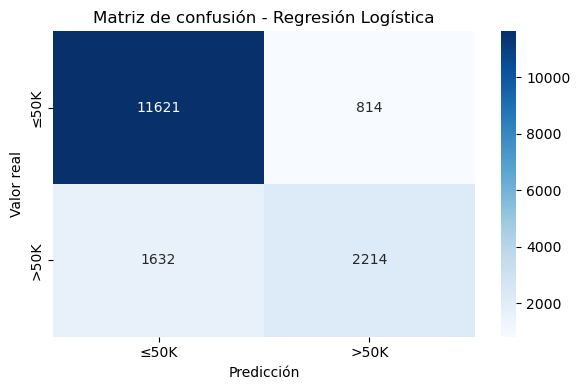

In [49]:
plt.figure(figsize=(6,4))
sns.heatmap(matrizRLog, annot=True, fmt="d", cmap="Blues", xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"])
plt.title("Matriz de confusión - Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

La matriz muestra 11.621 negativos y 2.214 positivos correctamente clasificados, con 814 falsos positivos y 1.632 falsos negativos. La regresión logística recupera el 57,57% de las personas >50K, el mayor Recall observado, aunque deja sin detectar al 42,43%. Su Precision positiva es del 73,12%; la mayor recuperación viene acompañada de más falsos positivos que en los otros modelos.

In [50]:
predRLog.unpersist()

DataFrame[independientes: vector, independientesEscaladas: vector, Salario: double, rawPrediction: vector, probability: vector, prediction: double]

#### Conclusión de la evaluación
La regresión logística alcanza una Accuracy de 84,98%, un F1 positivo de 0,6442 y un AUC-ROC de 0,9025. Presenta el mayor Recall, 57,57%, aunque su ventaja sobre GBT corresponde solo a tres personas. Es una referencia competitiva, pero sus 1.632 falsos negativos muestran que todavía deja sin reconocer una parte importante de los ingresos altos.

### Árbol de Decisión

Divide los datos mediante reglas sucesivas. Puede capturar relaciones no lineales y permite contrastar la sencillez de un árbol con los ensambles.

In [51]:
Arbol = DecisionTreeClassifier(featuresCol="independientes", labelCol="Salario", maxDepth=5, maxBins=32, seed=1055)

In [52]:
modeloArbol = Arbol.fit(train)

In [53]:
predArbol = modeloArbol.transform(test).cache()

#### Evaluación de Árbol de Decisión

In [54]:
accuracyArbol = evaluadorAccuracy.evaluate(predArbol)
AUCArbol = evaluadorAUC.evaluate(predArbol)

In [55]:
conteosArbol = predArbol.groupBy("Salario", "prediction").count().collect()
matrizArbol = np.zeros((2, 2), dtype=int)
for fila in conteosArbol:
    matrizArbol[int(fila["Salario"]), int(fila["prediction"])] = fila["count"]
TNArbol, FPArbol, FNArbol, TPArbol = matrizArbol.ravel()
assert int(matrizArbol.sum()) == totalTest

In [56]:
precisionArbol = float(TPArbol / (TPArbol + FPArbol)) if TPArbol + FPArbol > 0 else 0.0
recallArbol = float(TPArbol / (TPArbol + FNArbol)) if TPArbol + FNArbol > 0 else 0.0
F1Arbol = float(2 * TPArbol / (2 * TPArbol + FPArbol + FNArbol)) if 2 * TPArbol + FPArbol + FNArbol > 0 else 0.0

In [57]:
resultadoArbol = {"Modelo": "Árbol de Decisión", "Accuracy": accuracyArbol, "Precision (+)": precisionArbol,
                  "Recall (+)": recallArbol, "F1 (+)": F1Arbol, "AUC-ROC": AUCArbol}
resultadosModelos.append(resultadoArbol)
print(pd.Series(resultadoArbol))

Modelo           Árbol de Decisión
Accuracy                  0.842086
Precision (+)             0.753479
Recall (+)                 0.49272
F1 (+)                    0.595818
AUC-ROC                   0.565513
dtype: object


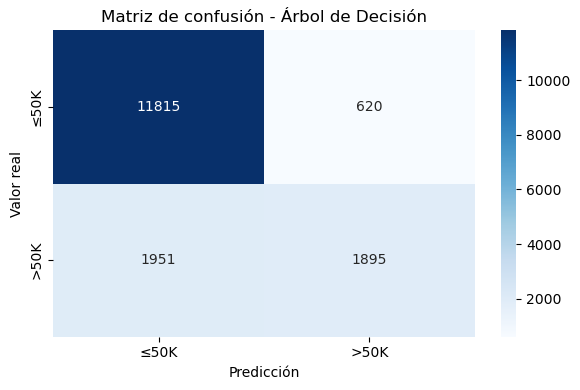

In [58]:
plt.figure(figsize=(6,4))
sns.heatmap(matrizArbol, annot=True, fmt="d", cmap="Blues", xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"])
plt.title("Matriz de confusión - Árbol de Decisión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

El árbol clasifica correctamente 11.815 negativos y 1.895 positivos, con 620 falsos positivos y 1.951 falsos negativos. Recupera el 49,27% de los positivos, menos de la mitad. Frente a la regresión logística evita 194 falsos positivos, pero pierde 319 aciertos positivos. Esto explica su mayor Precision y su menor Recall y F1.

In [59]:
predArbol.unpersist()

DataFrame[independientes: vector, independientesEscaladas: vector, Salario: double, rawPrediction: vector, probability: vector, prediction: double]

#### Conclusión de la evaluación
El árbol obtiene una Accuracy de 84,21%, una Precision positiva de 75,35% y un F1 de 0,5958. Su Recall de 49,27% indica que pierde más de la mitad de los positivos. Queda por debajo de ambos modelos lineales y de GBT en F1, aunque supera a Random Forest.

El AUC registrado, 0,5655, requiere una precisión metodológica. En DecisionTreeClassifier, rawPrediction contiene conteos de clases en la hoja. El evaluador ordena por el componente positivo, que depende también del tamaño de la hoja y no necesariamente conserva el orden de probability[1]. Por ello, este resultado no basta para afirmar que las probabilidades del árbol discriminan casi al azar. Se recomienda recalcular el AUC con la probabilidad positiva en una ejecución posterior. Se conserva aquí el resultado guardado, sin modificar el código ni inventar un valor corregido.

### Random Forest

Combina árboles entrenados con aleatoriedad para reducir la variabilidad de un árbol individual. Es pertinente para interacciones entre educación, ocupación y otras características.

In [60]:
RF = RandomForestClassifier(featuresCol="independientes", labelCol="Salario", numTrees=50, maxDepth=6, maxBins=32, seed=1055)

In [61]:
modeloRF = RF.fit(train)

In [62]:
predRF = modeloRF.transform(test).cache()

#### Evaluación de Random Forest

In [63]:
accuracyRF = evaluadorAccuracy.evaluate(predRF)
AUCRF = evaluadorAUC.evaluate(predRF)

In [64]:
conteosRF = predRF.groupBy("Salario", "prediction").count().collect()
matrizRF = np.zeros((2, 2), dtype=int)
for fila in conteosRF:
    matrizRF[int(fila["Salario"]), int(fila["prediction"])] = fila["count"]
TNRF, FPRF, FNRF, TPRF = matrizRF.ravel()
assert int(matrizRF.sum()) == totalTest

In [65]:
precisionRF = float(TPRF / (TPRF + FPRF)) if TPRF + FPRF > 0 else 0.0
recallRF = float(TPRF / (TPRF + FNRF)) if TPRF + FNRF > 0 else 0.0
F1RF = float(2 * TPRF / (2 * TPRF + FPRF + FNRF)) if 2 * TPRF + FPRF + FNRF > 0 else 0.0

In [66]:
resultadoRF = {"Modelo": "Random Forest", "Accuracy": accuracyRF, "Precision (+)": precisionRF,
                  "Recall (+)": recallRF, "F1 (+)": F1RF, "AUC-ROC": AUCRF}
resultadosModelos.append(resultadoRF)
print(pd.Series(resultadoRF))

Modelo           Random Forest
Accuracy              0.832934
Precision (+)          0.85056
Recall (+)            0.355174
F1 (+)                0.501101
AUC-ROC               0.896411
dtype: object


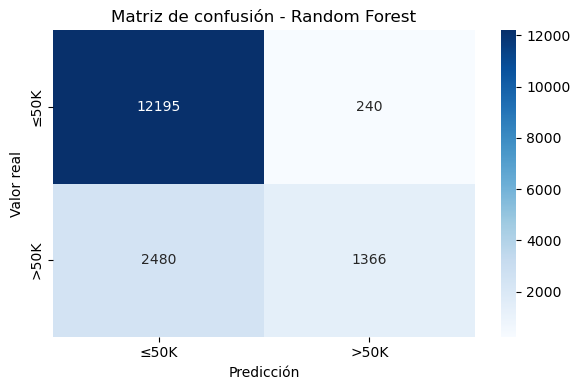

In [67]:
plt.figure(figsize=(6,4))
sns.heatmap(matrizRF, annot=True, fmt="d", cmap="Blues", xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"])
plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

Random Forest reconoce 12.195 negativos y 1.366 positivos, con 240 falsos positivos y 2.480 falsos negativos. Tiene la menor cantidad de falsas alarmas y la mayor Precision positiva, 85,06%, pero solo recupera el 35,52% de las personas >50K. Deja sin identificar al 64,48% de los positivos y favorece claramente la clase mayoritaria.

In [68]:
predRF.unpersist()

DataFrame[independientes: vector, independientesEscaladas: vector, Salario: double, rawPrediction: vector, probability: vector, prediction: double]

#### Conclusión de la evaluación
Random Forest obtiene una Accuracy de 83,29%, un AUC-ROC de 0,8964 y la mayor Precision positiva, 85,06%. Sin embargo, presenta el menor Recall, 35,52%, y el menor F1, 0,5011. La buena ordenación de puntuaciones no se traduce en una buena recuperación al umbral utilizado. Esta configuración reduce falsas alarmas, pero resulta limitada si la prioridad es encontrar la mayor cantidad de personas >50K.

### Gradient-Boosted Trees

Construye árboles secuenciales que corrigen errores del conjunto anterior. Permite estudiar si el aprendizaje progresivo mejora la clasificación de ingresos.

In [69]:
GBT = GBTClassifier(featuresCol="independientes", labelCol="Salario", maxIter=30, maxDepth=4, maxBins=32, stepSize=0.1, seed=1055)

In [70]:
modeloGBT = GBT.fit(train)

In [71]:
predGBT = modeloGBT.transform(test).cache()

#### Evaluación de Gradient-Boosted Trees

In [72]:
accuracyGBT = evaluadorAccuracy.evaluate(predGBT)
AUCGBT = evaluadorAUC.evaluate(predGBT)

In [73]:
conteosGBT = predGBT.groupBy("Salario", "prediction").count().collect()
matrizGBT = np.zeros((2, 2), dtype=int)
for fila in conteosGBT:
    matrizGBT[int(fila["Salario"]), int(fila["prediction"])] = fila["count"]
TNGBT, FPGBT, FNGBT, TPGBT = matrizGBT.ravel()
assert int(matrizGBT.sum()) == totalTest

In [74]:
precisionGBT = float(TPGBT / (TPGBT + FPGBT)) if TPGBT + FPGBT > 0 else 0.0
recallGBT = float(TPGBT / (TPGBT + FNGBT)) if TPGBT + FNGBT > 0 else 0.0
F1GBT = float(2 * TPGBT / (2 * TPGBT + FPGBT + FNGBT)) if 2 * TPGBT + FPGBT + FNGBT > 0 else 0.0

In [75]:
resultadoGBT = {"Modelo": "Gradient-Boosted Trees", "Accuracy": accuracyGBT, "Precision (+)": precisionGBT,
                  "Recall (+)": recallGBT, "F1 (+)": F1GBT, "AUC-ROC": AUCGBT}
resultadosModelos.append(resultadoGBT)
print(pd.Series(resultadoGBT))

Modelo           Gradient-Boosted Trees
Accuracy                       0.858977
Precision (+)                  0.769847
Recall (+)                     0.574883
F1 (+)                         0.658232
AUC-ROC                        0.910197
dtype: object


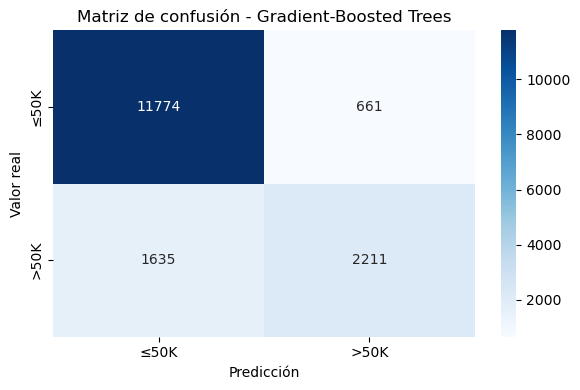

In [76]:
plt.figure(figsize=(6,4))
sns.heatmap(matrizGBT, annot=True, fmt="d", cmap="Blues", xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"])
plt.title("Matriz de confusión - Gradient-Boosted Trees")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

GBT clasifica correctamente 11.774 negativos y 2.211 positivos, con 661 falsos positivos y 1.635 falsos negativos. Frente a la regresión logística detecta solo tres positivos menos y evita 153 falsos positivos. Este intercambio eleva su Precision al 76,98% y su F1 a 0,6582, manteniendo un Recall prácticamente igual al de la regresión logística.

In [77]:
predGBT.unpersist()

DataFrame[independientes: vector, independientesEscaladas: vector, Salario: double, rawPrediction: vector, probability: vector, prediction: double]

#### Conclusión de la evaluación
GBT tiene el mejor resultado general bajo el criterio de F1 positivo, con 0,6582. También alcanza la mayor Accuracy, 85,90%, y el mayor AUC guardado, 0,9102. Su Recall de 57,49% es prácticamente igual al de la regresión logística, mientras la Precision mejora hasta 76,98%. Es el candidato preferido en esta comparación, aunque todavía deja 1.635 positivos sin detectar y requiere validación adicional.

### Máquina de vectores de soporte lineal

Busca una separación lineal de margen amplio. Complementa la regresión logística con un objetivo de aprendizaje distinto; sus márgenes se emplean para AUC sin convertirlos en probabilidades.

In [78]:
SVC = LinearSVC(featuresCol="independientesEscaladas", labelCol="Salario", maxIter=100, regParam=0.1, standardization=False)

In [79]:
modeloSVC = SVC.fit(train)

In [80]:
predSVC = modeloSVC.transform(test).cache()

#### Evaluación de Máquina de vectores de soporte lineal

In [81]:
accuracySVC = evaluadorAccuracy.evaluate(predSVC)
AUCSVC = evaluadorAUC.evaluate(predSVC)

In [82]:
conteosSVC = predSVC.groupBy("Salario", "prediction").count().collect()
matrizSVC = np.zeros((2, 2), dtype=int)
for fila in conteosSVC:
    matrizSVC[int(fila["Salario"]), int(fila["prediction"])] = fila["count"]
TNSVC, FPSVC, FNSVC, TPSVC = matrizSVC.ravel()
assert int(matrizSVC.sum()) == totalTest

In [83]:
precisionSVC = float(TPSVC / (TPSVC + FPSVC)) if TPSVC + FPSVC > 0 else 0.0
recallSVC = float(TPSVC / (TPSVC + FNSVC)) if TPSVC + FNSVC > 0 else 0.0
F1SVC = float(2 * TPSVC / (2 * TPSVC + FPSVC + FNSVC)) if 2 * TPSVC + FPSVC + FNSVC > 0 else 0.0

In [84]:
resultadoSVC = {"Modelo": "Máquina de vectores de soporte lineal", "Accuracy": accuracySVC, "Precision (+)": precisionSVC,
                  "Recall (+)": recallSVC, "F1 (+)": F1SVC, "AUC-ROC": AUCSVC}
resultadosModelos.append(resultadoSVC)
print(pd.Series(resultadoSVC))

Modelo           Máquina de vectores de soporte lineal
Accuracy                                      0.843929
Precision (+)                                 0.739802
Recall (+)                                    0.523401
F1 (+)                                        0.613065
AUC-ROC                                       0.894479
dtype: object


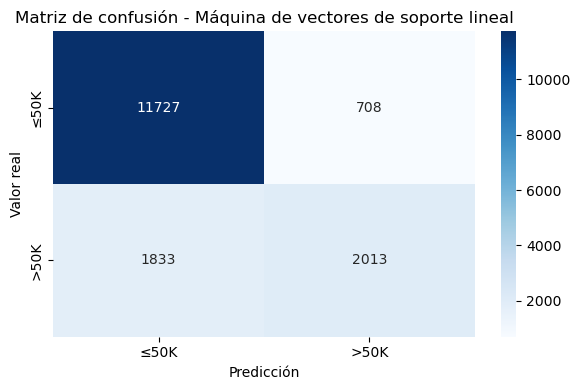

In [85]:
plt.figure(figsize=(6,4))
sns.heatmap(matrizSVC, annot=True, fmt="d", cmap="Blues", xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"])
plt.title("Matriz de confusión - Máquina de vectores de soporte lineal")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

LinearSVC identifica correctamente 11.727 negativos y 2.013 positivos, con 708 falsos positivos y 1.833 falsos negativos. Recupera el 52,34% de los positivos y alcanza una Precision de 73,98%. Frente a la regresión logística evita 106 falsos positivos, pero detecta 201 positivos menos. Con esta configuración queda por debajo de regresión logística y GBT en F1.

In [86]:
predSVC.unpersist()

DataFrame[independientes: vector, independientesEscaladas: vector, Salario: double, rawPrediction: vector, prediction: double]

#### Conclusión de la evaluación
LinearSVC alcanza una Accuracy de 84,39%, un F1 positivo de 0,6131 y un AUC-ROC de 0,8945, obtenido con sus márgenes de decisión. Ocupa el tercer lugar por F1 y supera al árbol y a Random Forest en esa métrica. Su Recall de 52,34% es inferior al de regresión logística y GBT. La separación lineal aporta capacidad predictiva, pero esta configuración no logra el mejor equilibrio entre Precision y Recall.

## Comparación final de los cinco modelos
Se compara el desempeño sobre el mismo conjunto original de prueba. La clasificación de modelos es descriptiva; elegir al ganador observando test no constituye una validación independiente para despliegue.

In [87]:
comparacionModelos = pd.DataFrame(resultadosModelos)
comparacionModelos.sort_values(["F1 (+)", "AUC-ROC"], ascending=False).round(4)

,Modelo,Accuracy,Precision (+),Recall (+),F1 (+),AUC-ROC
3,Gradient-Boosted Trees,0.8590,0.7698,0.5749,0.6582,0.9102
0,Regresión Logística,0.8498,0.7312,0.5757,0.6442,0.9025
4,Máquina de vectores de soporte lineal,0.8439,0.7398,0.5234,0.6131,0.8945
1,Árbol de Decisión,0.8421,0.7535,0.4927,0.5958,0.5655
2,Random Forest,0.8329,0.8506,0.3552,0.5011,0.8964


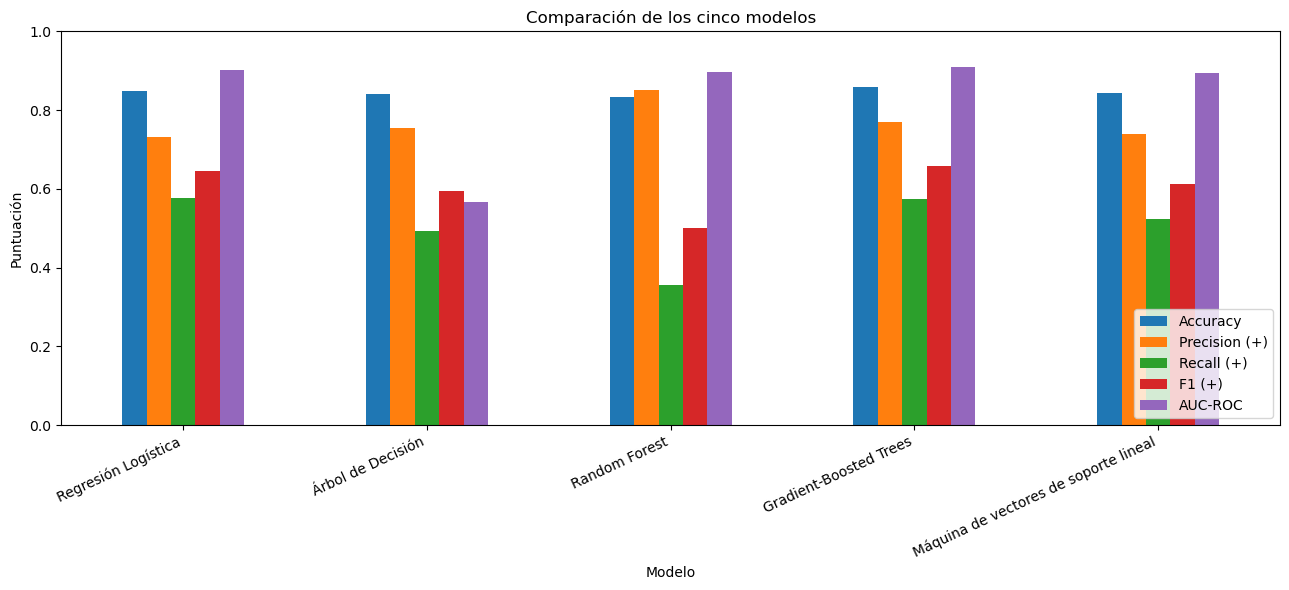

In [88]:
comparacionGrafica = comparacionModelos.set_index("Modelo")
comparacionGrafica.plot(kind="bar", figsize=(13,6))
plt.title("Comparación de los cinco modelos")
plt.xlabel("Modelo")
plt.ylabel("Puntuación")
plt.ylim(0,1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

GBT obtiene la mayor Accuracy, 0,8590, y el mayor F1 positivo, 0,6582. La regresión logística queda cerca con F1 de 0,6442 y el mayor Recall, 0,5757, frente a 0,5749 de GBT. Random Forest destaca en Precision, 0,8506, pero presenta el menor Recall y F1. Las barras de Accuracy son relativamente próximas y ocultan diferencias importantes en la recuperación de positivos. El AUC de 0,5655 del árbol corresponde al orden de sus conteos rawPrediction y requiere revisión con la probabilidad positiva antes de concluir que sus probabilidades discriminan casi al azar.

In [89]:
mejorGeneral = comparacionModelos.sort_values(["F1 (+)", "AUC-ROC"], ascending=False).iloc[0]
mayorRecall = comparacionModelos[comparacionModelos["Recall (+)"] == comparacionModelos["Recall (+)"].max()]
print("Mejor según F1 positivo, con AUC como desempate:", mejorGeneral["Modelo"])
print("Modelos con mayor Recall positivo:", mayorRecall["Modelo"].tolist())

Mejor según F1 positivo, con AUC como desempate: Gradient-Boosted Trees
Modelos con mayor Recall positivo: ['Regresión Logística']


In [90]:
claseMayoritaria = train.groupBy("Salario").count().orderBy(F.desc("count"), F.asc("Salario")).first()["Salario"]
accuracyBase = test.filter(F.col("Salario") == claseMayoritaria).count() / totalTest
print("Accuracy de predecir siempre la clase mayoritaria de train:", round(accuracyBase, 4))

Accuracy de predecir siempre la clase mayoritaria de train: 0.7638


Predecir siempre ≤50K alcanza una Accuracy de 0,7638 en prueba, pero no identifica a ninguna persona >50K. Todos los modelos superan esa referencia; GBT llega a 0,8590, una mejora aproximada de 9,52 puntos porcentuales. Accuracy resume los aciertos totales, pero no sustituye la evaluación de la clase positiva.

### Análisis de resultados
GBT ocupa el primer lugar por F1 positivo, con 0,6582, seguido de regresión logística con 0,6442, LinearSVC con 0,6131, árbol de decisión con 0,5958 y Random Forest con 0,5011. La ventaja de GBT sobre regresión logística es de 0,0141 en F1 y de aproximadamente 0,92 puntos porcentuales en Accuracy. Estas diferencias describen esta ejecución; no se hicieron repeticiones ni pruebas de significancia que permitan afirmar una superioridad estable.

La regresión logística detecta 2.214 de los 3.846 positivos y GBT detecta 2.211. La diferencia de Recall es de apenas 0,08 puntos porcentuales. A cambio de esos tres positivos adicionales, la regresión logística produce 814 falsos positivos frente a 661 de GBT. Por ello, GBT ofrece el mejor equilibrio observado y la regresión logística conserva la mayor recuperación numérica.

Entre los métodos lineales, regresión logística supera a LinearSVC en Accuracy, Recall, F1 y AUC, aunque LinearSVC tiene una Precision ligeramente mayor. El árbol individual alcanza una Precision de 75,35%, pero pierde el 50,73% de los positivos. Su AUC de 0,5655 debe interpretarse con la limitación del uso de conteos rawPrediction descrita en su evaluación; no se dispone de un AUC recalculado con probabilidades.

Los ensambles no mejoran todas las métricas por igual. GBT supera al árbol en Accuracy, Precision, Recall y F1. Random Forest eleva la Precision hasta 85,06% y reduce los falsos positivos a 240, pero deja 2.480 positivos sin detectar. Su AUC de 0,8964 y Recall de 35,52% muestran que ordenar bien las puntuaciones no garantiza una buena recuperación con el umbral de clasificación actual.

La prueba contiene 12.435 negativos y 3.846 positivos. La clase mayoritaria representa el 76,38%, por lo que una predicción constante ya obtiene una Accuracy alta. Aunque los modelos alcanzan entre 83,29% y 85,90% de Accuracy, sus Recall positivos oscilan entre 35,52% y 57,57%. Precision mide cuántas predicciones positivas son correctas; Recall mide cuántos positivos reales se detectan; F1 resume el equilibrio entre ambas. Esto explica por qué Random Forest puede tener la mayor Precision y, al mismo tiempo, el menor F1.

### Conclusiones y recomendaciones
La preparación conservó los 32.561 registros de entrenamiento y los 16.281 de prueba. Los faltantes aparecieron en variables categóricas y el Pipeline produjo vectores de 98 componentes. Ajustar sus etapas solo con entrenamiento evita aprender categorías, imputaciones y escalas a partir de prueba.

GBT es el modelo preferido en esta ejecución por su F1 positivo de 0,6582 y Accuracy de 85,90%. Mantiene casi la misma recuperación que la regresión logística con 153 falsos positivos menos. La regresión logística sigue siendo una alternativa competitiva, pero su ventaja de tres positivos no demuestra una superioridad general.

Random Forest confirma que una Precision alta no basta cuando se quiere identificar a las personas de ingresos altos: sus 2.480 falsos negativos explican su menor F1. Incluso los modelos con mayor Recall omiten aproximadamente el 42% de los positivos. La elección debe considerar el costo de ambos tipos de error y no solo Accuracy.

Spark permitió completar la limpieza, agregación, preparación y entrenamiento de cinco clasificadores; Pandas se utilizó para resúmenes pequeños y visualizaciones. Este flujo demuestra la aplicación de MLlib, pero el tamaño de Adult y esta ejecución no permiten afirmar que se haya demostrado escalabilidad a grandes volúmenes.


### README / Reproducibility (English)
This notebook compares five PySpark MLlib classifiers on UCI Adult. Open it in the supplied Jupyter environment using the original Spark kernel and run cells from top to bottom. It requires the existing Spark installation, Java, findspark, NumPy, Pandas, Matplotlib, Seaborn. Spark UI requests port 37016.

The notebook automatically downloads the official UCI ZIP and extracts `adult.data` and `adult.test` into the local `datos_adult` directory. Internet access to UCI and write permission in the working directory are required. File contents are read on the driver and passed to Spark as distributed text, so executor access to the local directory is unnecessary.

Use a fresh kernel for a full rerun. The original train/test split is preserved. Learned preprocessing is fitted on training data only. Positive-class precision, recall and F1 refer to income >50K. The saved execution outputs and figures are preserved. Comments and conclusions describe those results; the notebook was not rerun during annotation. The decision tree AUC uses raw leaf class counts and should be reassessed using positive-class probabilities before comparing probability ranking performance. This embedded README covers the optional English documentation item; no repository publication is claimed.

### Referencias
- Becker, B. y Kohavi, R. Census Income (Adult), UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/20/census+income , DOI: https://doi.org/10.24432/C5XW20
- Rodríguez Murillo, S. `RodriguezMurilloICTUS_1055.ipynb`. Material base de la asignatura: estructura, membrete y entorno.
- Apache Spark. Classification and regression: https://spark.apache.org/docs/latest/ml-classification-regression.html
- Apache Spark. ML Pipelines: https://spark.apache.org/docs/latest/ml-pipeline.html
- Apache Spark. Feature transformers: https://spark.apache.org/docs/latest/ml-features.html
- İlhan Sevval. Classification Models with Pyspark in Bank Dataset. https://www.kaggle.com/code/ilhansevval/classification-models-with-pyspark-in-bank-dataset/notebook
- Aditi Mulye. Adult Income Dataset | From Scratch. https://www.kaggle.com/code/aditimulye/adult-income-dataset-from-scratch

Las guías de Kaggle se incluyen como referencias indicadas en el enunciado; sus páginas no expusieron contenido legible en la consulta. No se atribuye código específico a ellas. La implementación sigue principalmente ICTUS y las APIs oficiales de Spark.

### Cierre de la sesión
Ejecutar al terminar de revisar las salidas; libera los datos en memoria y la sesión de este taller.

In [91]:
sparkRodriguezM.stop()